# 2.2 – EDA: vấn đề chất lượng ảnh trong HAM10000 (theo Chương 3)

**Phạm vi:** chỉ các vấn đề chất lượng ảnh mà **Chương 3 – Nâng cao chất lượng ảnh** xử lý được
(độ sáng, histogram, tương phản, nhiễu). Lông được xếp vào nhóm nhiễu (nhiễu dạng nét tối mảnh).

| # | Vấn đề | Chỉ số (đo trên mọi ảnh) | Dấu hiệu theo Ch.3 | Xử lý dự kiến (2.5) |
|---|---|---|---|---|
| 1 | Viền tối ống soi | % diện tích vùng đen (≤ 20) nối mép ảnh | Đỉnh ở mức xám ~0 trong histogram | Bỏ viền khỏi ảnh / thống kê |
| 2 | Quá sáng / quá tối | % pixel "trắng bạc"; mức xám trung bình | Histogram lệch phải / trái | Biến đổi gamma, log, cân bằng histogram |
| 3 | Tương phản thấp | Mức xám da − mức xám tổn thương (tách bằng Otsu) | Histogram hẹp, 1 đỉnh | Giãn histogram, cân bằng histogram |
| 4 | Sáng không đều | Ô nền sáng nhất − tối nhất (lưới 4×4) | Một ngưỡng toàn cục không dùng được | Cân bằng histogram cục bộ (CLAHE) |
| 5 | Nhiễu Gauss | Std phần dư (ảnh − lọc trung vị 3×3) ở vùng phẳng | Mô hình g = f + η | Lọc trung bình / Gauss / trung vị |
| 6 | Nhiễu muối–tiêu | % pixel xung (cực trị lệch xa trung vị lân cận) | Nhiễu xung | Lọc trung vị |
| 7 | Lông | % pixel lông (black-hat) | Nhiễu dạng nét tối, lọc trung vị nhỏ không xóa được | Black-hat + inpainting |

**Ngưỡng:** quy tắc ngoại lai của **box plot** (> Q3 + 1.5·IQR); ngưỡng tuyệt đối khi phân phối dồn về 0.

**Kiểm định:** 1 ảnh / lesion (ảnh cùng lesion không độc lập); Kruskal–Wallis + effect size ε² (0.01 nhỏ / 0.08 vừa / 0.26 lớn).

**Liên hệ lỗi CNN:** TODO – chờ dự đoán baseline ngoài mẫu (mục 5 tự chạy khi có file).

## 1. Thiết lập và tải chỉ số

In [1]:
import sys, warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

sys.path.insert(0, str(Path.cwd()))
from src.eda import quality_metrics as qm, stats as st, plots as pl, flags as fl

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
EDA_DIR, SET_DIR = Path("outputs/eda"), Path("outputs/eda/problem_sets")
SET_DIR.mkdir(parents=True, exist_ok=True)
pl.setup_style()
CLASSES, CC = pl.CLASSES, pl.CLASS_COLORS
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

if not (EDA_DIR / "quality_metrics.csv").exists():
    qm.compute_all(n_jobs=8)          # ~3–8 phút; hoặc: python -X utf8 -m src.eda.quality_metrics --jobs 8
df = pd.read_csv(EDA_DIR / "quality_metrics.csv")
assert df["error"].isna().all(), "Có ảnh đo lỗi"
HIST = np.load(EDA_DIR / "hist_gray.npy")       # (N, 256) histogram mức xám, cùng thứ tự với df

flags, RULES = fl.compute_flags(df)
df = pd.concat([df, flags.add_prefix("F_")], axis=1)
THR = RULES.set_index("key").threshold
les = st.one_per_lesion(df)                     # tập kiểm định: 1 ảnh / lesion
print(f"{len(df)} ảnh | {df.lesion_id.nunique()} lesion | tập kiểm định n = {len(les)}")
print("Kích thước ảnh:", df[["width", "height"]].drop_duplicates().values.tolist(), "| mode:", df["mode"].unique())
RULES

10015 ảnh | 7470 lesion | tập kiểm định n = 7470
Kích thước ảnh: [[600, 450]] | mode: <StringArray>
['RGB']
Length: 1, dtype: str


,key,problem,metric,threshold,rule
0,vignette,Viền tối do ống soi,vignette_frac,0.010,> 1% diện tích ảnh là vùng đen (<= 20/255) nối...
1,overexposed,Quá sáng / bạc màu,bright_frac,0.100,> 10% vùng nhìn thấy là pixel 'trắng bạc' (V >...
2,underexposed,Quá tối,gray_mean,105.576,mức xám trung bình < Q1 − 1.5·IQR (box plot)
3,low_contrast,Tương phản tổn thương–da thấp,contrast,20.000,mức xám da − mức xám tổn thương < 20 (≈ 8% dải...
4,uneven_illum,Sáng không đều,illum_range,38.000,ô nền sáng nhất − tối nhất (12 ô viền lưới 4x4...
5,noise,Nhiễu Gauss,noise_sigma,2.160,std phần dư (ảnh − trung vị 3x3) ở vùng phẳng ...
6,impulse,Nhiễu muối–tiêu,impulse_frac,0.001,> 0.1% pixel là xung (cực trị lệch >= 60 so vớ...
7,hair,Lông (nhiễu dạng nét),hair_frac,0.058,"tỉ lệ pixel lông (black-hat 17x17 >= 20, bỏ đố..."


### Hàm dùng chung

In [2]:
def pct_by_class(ax, key, letter="c"):
    """% ảnh bị gắn cờ theo lớp (1 ảnh/lesion)."""
    t = les.groupby("dx")["F_" + key].mean().reindex(CLASSES) * 100
    ax.bar(CLASSES, t, color=[CC[c] for c in CLASSES], width=0.7)
    for i, v in enumerate(t):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=6.5)
    ax.set_ylabel("% ảnh bị gắn cờ")
    ax.set_title(f"({letter}) Theo lớp (1 ảnh/lesion)", loc="left")
    ax.grid(axis="x", visible=False)
    return t


def hist_thr(ax, x, thr, xlabel, side="high", log=False, bins=80, letter="a"):
    """Phân phối chỉ số trên mọi ảnh + đường ngưỡng + số ảnh vượt ngưỡng."""
    x = pd.Series(x).dropna()
    if log:
        x = x[x > 0]
        bins = np.logspace(np.log10(x.min()), np.log10(x.max()), bins)
        ax.set_xscale("log")
    ax.hist(x, bins=bins, color=pl.OK_COLOR)
    ax.axvline(thr, color=pl.FLAG_COLOR, ls="--", lw=1.2)
    n = int((x > thr).sum() if side == "high" else (x < thr).sum())
    ax.text(0.98, 0.95, f"ngưỡng = {thr:.3g}\n{n} ảnh", transform=ax.transAxes,
            ha="right", va="top", color=pl.FLAG_COLOR, fontsize=7.5)
    ax.set_xlabel(xlabel); ax.set_ylabel("Số ảnh")
    ax.set_title(f"({letter}) Phân phối ({len(x)} ảnh)", loc="left")


def kw(metric, group="dx"):
    r = st.kruskal_eps2(les, metric, group)
    return f"Kruskal–Wallis theo {group}: ε² = {r['eps2']:.3f} ({st.eps2_magnitude(r['eps2'])}), p = {r['p']:.1e}"


def save_set(key, metric, ascending=False):
    s = df.loc[df["F_" + key], ["image_id", "lesion_id", "dx", "split", "path", metric]].sort_values(metric, ascending=ascending)
    s.to_csv(SET_DIR / f"{key}.csv", index=False)
    print(f"[{key}] {len(s)} ảnh ({len(s) / len(df):.1%}), {s.lesion_id.nunique()} lesion → {SET_DIR / (key + '.csv')}")
    return s


def grid(key, metric, ascending=False, fmt="{:.3g}", label=None):
    """Hàng 1–2: 12 ảnh nặng nhất theo chỉ số; hàng 3–4: 12 ảnh ngẫu nhiên (seed 42) trong nhóm bị gắn cờ."""
    s = df.loc[df["F_" + key]].sort_values(metric, ascending=ascending)
    top, rest = s.head(12), s.iloc[12:]
    rows = pd.concat([top, rest.sample(min(12, len(rest)), random_state=SEED)])
    pl.image_grid(rows, lambda r: f"{r['dx']} | {fmt.format(r[metric])}", ncols=6, name=f"grid_{key}",
                  suptitle=f"{label or key}: hàng 1–2 = 12 ảnh nặng nhất theo {metric}; "
                           f"hàng 3–4 = ảnh ngẫu nhiên (seed 42) trong {len(s)} ảnh bị gắn cờ")
    plt.show()


def mean_hist(mask):
    return np.nanmean(HIST[np.asarray(mask)], axis=0) * 100

## 2. Cách đo – minh họa từng bước trên một ảnh
Ảnh chọn theo quy tắc: trong nhóm "lông", ảnh có `hair_frac` và `contrast` cùng gần trung vị nhất (không chọn ảnh đẹp).

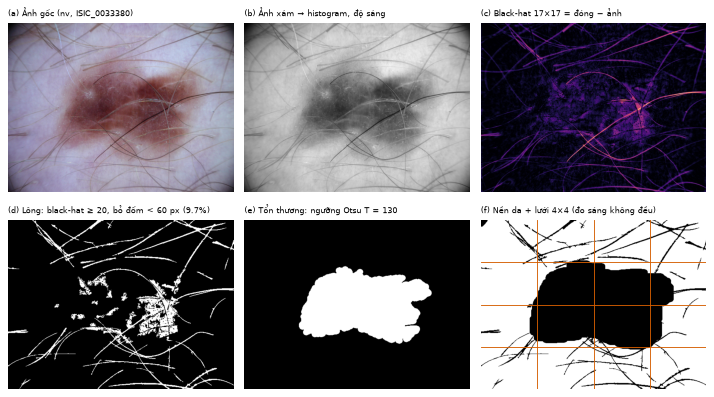

In [3]:
s_h = df[df.F_hair]
score = (s_h.hair_frac.rank(pct=True) - 0.5).abs() + (s_h.contrast.rank(pct=True) - 0.5).abs()
ex = s_h.loc[score.idxmin()]
A = qm.analyze_image(ex.path)
fig, axes = plt.subplots(2, 3, figsize=(9, 5.2))
panels = [
    (A["rgb"], None, f"(a) Ảnh gốc ({ex.dx}, {ex.image_id})"),
    (A["gray"], "gray", "(b) Ảnh xám → histogram, độ sáng"),
    (A["blackhat"], "magma", "(c) Black-hat 17×17 = đóng − ảnh"),
    (A["hair"], "gray", f"(d) Lông: black-hat ≥ 20, bỏ đốm < 60 px ({ex.hair_frac:.1%})"),
    (A["lesion"], "gray", f"(e) Tổn thương: ngưỡng Otsu T = {A['otsu_t']:.0f}"),
    (A["skin"], "gray", "(f) Nền da + lưới 4×4 (đo sáng không đều)"),
]
for ax, (im, cmap, t) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=cmap); ax.set_title(t, fontsize=7.5, loc="left"); ax.axis("off")
h, w = A["gray"].shape
for k in range(1, 4):
    axes[1, 2].axhline(k * h / 4, color="#D55E00", lw=0.8); axes[1, 2].axvline(k * w / 4, color="#D55E00", lw=0.8)
fig.tight_layout(); pl.savefig(fig, "fig01_how_we_measure", raster=True); plt.show()

## 3. Từng vấn đề
### 3.1 Viền tối do ống soi

**Mô tả lỗi.** Bốn góc (hoặc cả viền) ảnh bị **đen kịt**, phần nhìn thấy được có dạng hình tròn/bầu dục ở giữa.

**Nguyên nhân.** Ống kính máy soi da (dermoscope) có miệng tròn; khi cảm biến chữ nhật chụp qua miệng tròn, phần ngoài vòng tròn không nhận được ánh sáng.

**Dấu hiệu nhận biết bằng mắt:**
- Góc ảnh đen (mức xám gần 0), ranh giới giữa vùng đen và vùng da là một **cung tròn**;
- vùng đen nối liền với mép ảnh (khác với tổn thương tối nằm giữa ảnh);
- thường kèm theo da ở gần viền tối dần (tối dần trước khi đen hẳn).

**Dấu hiệu trên histogram / số liệu:** một **đỉnh nhọn ở mức xám 0–20** tách rời khỏi phần histogram của da; tỉ lệ diện tích vùng đen nối mép > 1%.

**Tác hại:** viền đen chiếm dải mức xám thấp → cân bằng histogram / chuẩn hóa độ sáng bị kéo lệch; CNN có thể dùng "có viền tròn" như một dấu hiệu của thiết bị chụp.

**Cách đo và bằng chứng trong notebook:**

**Đo:** phân ngưỡng mức xám ≤ 20 → phép mở 15×15 xóa sợi lông tối → giữ vùng đen nối với mép ảnh.

**Vì sao là vấn đề (Ch.3):** viền đen tạo một đỉnh giả ở mức xám ~0 trong histogram. Cân bằng histogram toàn ảnh
sẽ dành một phần dải mức xám cho viền này thay vì cho vùng da/tổn thương.

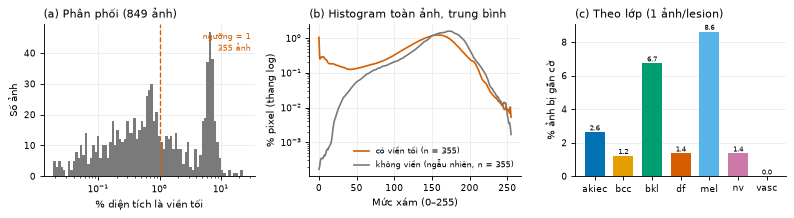

% pixel mức xám 0–20: 5.56% (có viền) vs 0.018% (không viền)
Theo lớp (%): {'akiec': 2.6, 'bcc': 1.2, 'bkl': 6.7, 'df': 1.4, 'mel': 8.6, 'nv': 1.4, 'vasc': 0.0}
[vignette] 355 ảnh (3.5%), 345 lesion → outputs\eda\problem_sets\vignette.csv


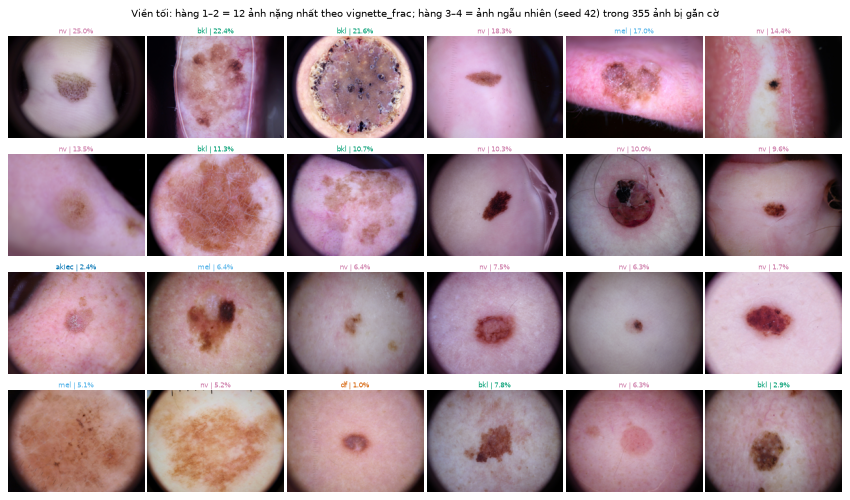

In [4]:
key = "vignette"
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
hist_thr(axes[0], df.vignette_frac * 100, fl.VIG_T * 100, "% diện tích là viền tối", log=True)
# histogram TOÀN ẢNH (kể cả viền) – HIST đã lưu chỉ tính vùng nhìn thấy nên tính lại ở đây
def full_hist(paths):
    return np.mean([np.bincount(cv2.imread(p, cv2.IMREAD_GRAYSCALE).ravel(), minlength=256) / (600 * 450)
                    for p in paths], axis=0) * 100
g1 = df[df.F_vignette]; g0 = df[df.vignette_frac == 0].sample(len(g1), random_state=SEED)
H1, H0 = full_hist(g1.path), full_hist(g0.path)
ax = axes[1]
ax.plot(H1, color=pl.FLAG_COLOR, label=f"có viền tối (n = {len(g1)})")
ax.plot(H0, color=pl.OK_COLOR, label=f"không viền (ngẫu nhiên, n = {len(g0)})")
ax.set_yscale("log"); ax.set_xlabel("Mức xám (0–255)"); ax.set_ylabel("% pixel (thang log)")
ax.set_title("(b) Histogram toàn ảnh, trung bình", loc="left"); ax.legend(frameon=False, fontsize=7)
pct = pct_by_class(axes[2], key)
fig.tight_layout(); pl.savefig(fig, "fig02_vignette"); plt.show()
print(f"% pixel mức xám 0–20: {H1[:21].sum():.2f}% (có viền) vs {H0[:21].sum():.3f}% (không viền)")
print("Theo lớp (%):", pct.round(1).to_dict())
save_set(key, "vignette_frac"); grid(key, "vignette_frac", fmt="{:.1%}", label="Viền tối")

### 3.2 Quá sáng (bạc màu) và quá tối

**Mô tả lỗi.** Ảnh **quá sáng**: da gần như trắng, màu nhạt "bạc", chi tiết vùng sáng (vân da, mạng sắc tố nhạt) bị mất.
Ảnh **quá tối**: toàn ảnh tối, khó phân biệt tổn thương với da.

**Nguyên nhân.** Đèn LED của máy soi quá mạnh / quá gần, phơi sáng tự động sai, da phản xạ mạnh (có gel, dầu).

**Dấu hiệu nhận biết bằng mắt (quá sáng):**
- nền da trắng hoặc hồng rất nhạt, gần như không còn màu;
- tổn thương trông như "dán" lên nền trắng, viền mờ phần nhạt bị mất;
- không thấy vân da / mao mạch ở vùng sáng.

**Dấu hiệu trên histogram / số liệu:** histogram **dồn về bên phải** (mức xám 200–255), nhiều pixel chạm 250–255;
trong HSV: độ sáng V rất cao và độ bão hòa S rất thấp (pixel "trắng bạc"). Quá tối thì ngược lại: histogram dồn về bên trái.

**Tác hại:** chi tiết nằm trong dải mức xám bị nén (vài mức xám cuối) → mất thông tin kết cấu; màu da khác thường làm lệch đặc trưng màu.

**Cách đo và bằng chứng trong notebook:**

**Đo:** pixel "trắng bạc" = rất sáng (V ≥ 235) và gần như mất màu (S ≤ 40) – da bình thường vẫn có màu.

**Vì sao là vấn đề (Ch.3):** histogram dồn về phía 200–255 → chi tiết vùng sáng bị nén vào ít mức xám.
Biến đổi gamma (γ > 1) hoặc cân bằng histogram trải lại dải này.
Quá tối: mức xám trung bình < Q1 − 1.5·IQR.

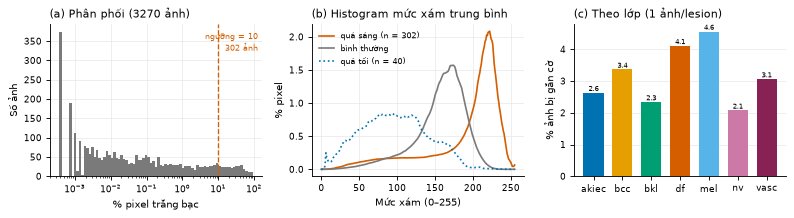

Mức xám TB: 191.2 (quá sáng) vs 155.8 (còn lại); độ bão hòa da S: 32.1 vs 63.1
% pixel mức xám ≥ 200: 62.2% (quá sáng) vs 5.1% (còn lại)
Quá tối: ngưỡng 105.6, 40 ảnh
Theo lớp (%): {'akiec': 2.6, 'bcc': 3.4, 'bkl': 2.3, 'df': 4.1, 'mel': 4.6, 'nv': 2.1, 'vasc': 3.1}
[overexposed] 302 ảnh (3.0%), 244 lesion → outputs\eda\problem_sets\overexposed.csv


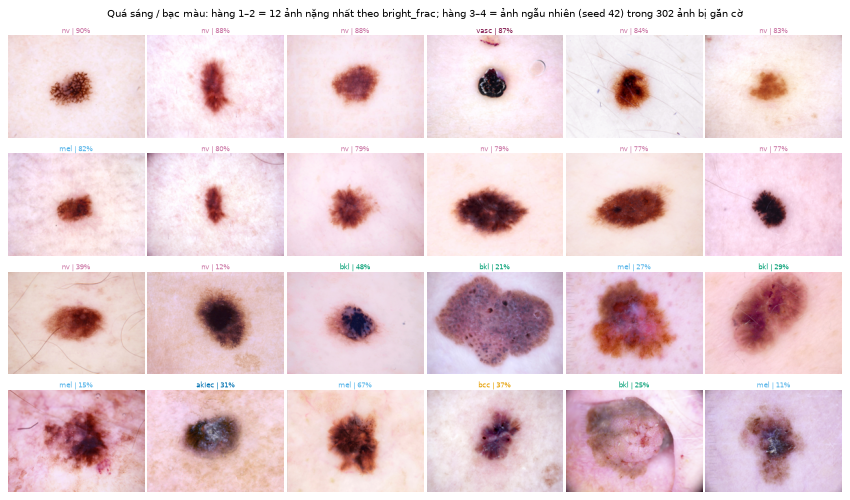

[underexposed] 40 ảnh (0.4%), 36 lesion → outputs\eda\problem_sets\underexposed.csv


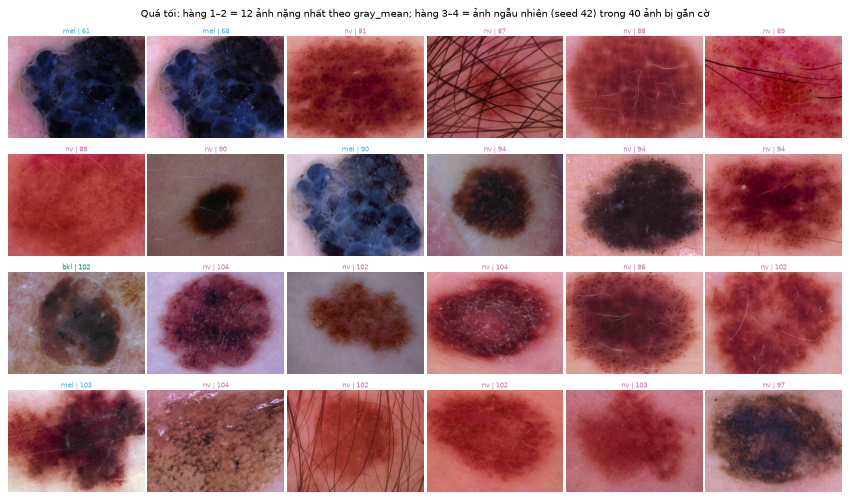

In [5]:
key = "overexposed"
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
hist_thr(axes[0], df.bright_frac * 100, 10, "% pixel trắng bạc", log=True)
ax = axes[1]
ax.plot(mean_hist(df.F_overexposed), color=pl.FLAG_COLOR, label=f"quá sáng (n = {df.F_overexposed.sum()})")
ax.plot(mean_hist(~df.F_overexposed & ~df.F_underexposed & ~df.F_vignette), color=pl.OK_COLOR, label="bình thường")
ax.plot(mean_hist(df.F_underexposed), color="#0072B2", ls=":", label=f"quá tối (n = {df.F_underexposed.sum()})")
ax.set_xlabel("Mức xám (0–255)"); ax.set_ylabel("% pixel")
ax.set_title("(b) Histogram mức xám trung bình", loc="left"); ax.legend(frameon=False, fontsize=7)
pct = pct_by_class(axes[2], key)
fig.tight_layout(); pl.savefig(fig, "fig03_exposure"); plt.show()
o = df.F_overexposed
print(f"Mức xám TB: {df.gray_mean[o].median():.1f} (quá sáng) vs {df.gray_mean[~o].median():.1f} (còn lại); "
      f"độ bão hòa da S: {df.skin_S[o].median():.1f} vs {df.skin_S[~o].median():.1f}")
print(f"% pixel mức xám ≥ 200: {mean_hist(o)[200:].sum():.1f}% (quá sáng) vs {mean_hist(~o)[200:].sum():.1f}% (còn lại)")
print(f"Quá tối: ngưỡng {THR['underexposed']:.1f}, {df.F_underexposed.sum()} ảnh")
print("Theo lớp (%):", pct.round(1).to_dict())
save_set(key, "bright_frac"); grid(key, "bright_frac", fmt="{:.0%}", label="Quá sáng / bạc màu")
save_set("underexposed", "gray_mean", ascending=True)
grid("underexposed", "gray_mean", ascending=True, fmt="{:.0f}", label="Quá tối")

### 3.3 Tương phản tổn thương–da thấp

**Mô tả lỗi.** Tổn thương có mức sáng/màu **gần giống da xung quanh** – khó thấy tổn thương bắt đầu và kết thúc ở đâu.

**Nguyên nhân.** Bản chất tổn thương (nhạt màu, phẳng, ít sắc tố – hay gặp ở bcc, akiec, bkl) cộng với điều kiện chụp (ánh sáng khuếch tán, quá sáng).

**Dấu hiệu nhận biết bằng mắt:**
- tổn thương nhạt, hồng/nâu rất nhẹ, "chìm" vào nền da;
- **bờ tổn thương mờ**, không vẽ được đường viền rõ ràng;
- ảnh tổng thể trông "phẳng", ít vùng rất sáng và rất tối.

**Dấu hiệu trên histogram / số liệu:** histogram **hẹp và chỉ có 1 đỉnh** (da và tổn thương chồng lên nhau) – ảnh tương phản tốt có 2 đỉnh tách rời;
khoảng phân vị 5–95 nhỏ, độ lệch chuẩn mức xám nhỏ; chênh lệch mức xám da − tổn thương nhỏ (< 20).

**Tác hại:** bờ và hình dạng tổn thương (dấu hiệu chẩn đoán quan trọng) khó nhìn thấy với CNN; phân ngưỡng tách tổn thương dễ sai.

**Cách đo và bằng chứng trong notebook:**

**Đo:** ngưỡng Otsu (Ch.5) tách vùng tối (tổn thương) khỏi da → chỉ số = mức xám TB da − mức xám TB tổn thương.

**Vì sao là vấn đề (Ch.3):** ảnh tương phản thấp có histogram hẹp, **1 đỉnh** (da và tổn thương chồng lên nhau);
ảnh tương phản tốt có 2 đỉnh tách rời. Giãn / cân bằng histogram kéo hai nhóm mức xám ra xa nhau.
Mask Otsu chỉ là ước lượng thô (bộ dữ liệu không có mask chuẩn).

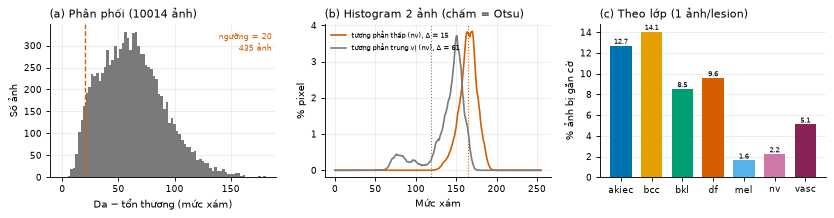

Ví dụ: ISIC_0034072 (thấp), ISIC_0034178 (trung vị)
Khoảng phân vị 5–95 của histogram: 38 (tương phản thấp) vs 84 (còn lại) mức xám; std mức xám: 12.3 vs 26.4
Độ nhạy theo ngưỡng: {15: 141, 20: 435, 25: 859}
Theo lớp (%): {'akiec': 12.7, 'bcc': 14.1, 'bkl': 8.5, 'df': 9.6, 'mel': 1.6, 'nv': 2.2, 'vasc': 5.1}
Kruskal–Wallis theo dx: ε² = 0.115 (vừa), p = 7.6e-183
[low_contrast] 435 ảnh (4.3%), 381 lesion → outputs\eda\problem_sets\low_contrast.csv


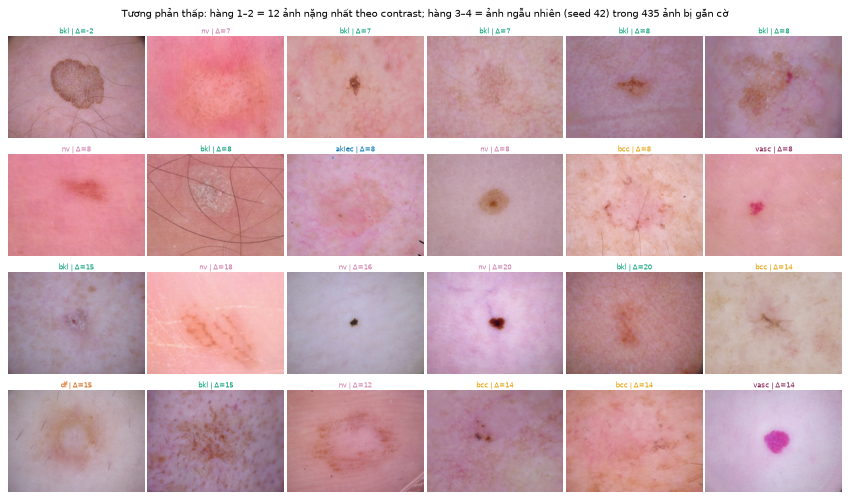

In [6]:
key = "low_contrast"
fig, axes = plt.subplots(1, 3, figsize=(10.5, 2.8))
hist_thr(axes[0], df.contrast, fl.LOW_CONTRAST_T, "Da − tổn thương (mức xám)", side="low")
ax = axes[1]
q = df.contrast.median()
ex_lo = df[df.F_low_contrast & (df.vignette_frac == 0)].sample(1, random_state=SEED).iloc[0]
ex_hi = df[((df.contrast - q).abs() < 2) & (df.vignette_frac == 0)].sample(1, random_state=SEED).iloc[0]
for r, c, lab in [(ex_lo, pl.FLAG_COLOR, "tương phản thấp"), (ex_hi, pl.OK_COLOR, "tương phản trung vị")]:
    ax.plot(HIST[r.name] * 100, color=c, label=f"{lab} ({r.dx}), Δ = {r.contrast:.0f}")
    ax.axvline(r.otsu_t, color=c, ls=":", lw=1)
ax.set_xlabel("Mức xám"); ax.set_ylabel("% pixel"); ax.legend(frameon=False, fontsize=6.5, loc="upper left")
ax.set_title("(b) Histogram 2 ảnh (chấm = Otsu)", loc="left")
pct = pct_by_class(axes[2], key)
fig.tight_layout(); pl.savefig(fig, "fig04_low_contrast"); plt.show()
lc = df.F_low_contrast
print(f"Ví dụ: {ex_lo.image_id} (thấp), {ex_hi.image_id} (trung vị)")
print(f"Khoảng phân vị 5–95 của histogram: {(df.gray_p95 - df.gray_p5)[lc].median():.0f} (tương phản thấp) "
      f"vs {(df.gray_p95 - df.gray_p5)[~lc].median():.0f} (còn lại) mức xám; "
      f"std mức xám: {df.gray_std[lc].median():.1f} vs {df.gray_std[~lc].median():.1f}")
print("Độ nhạy theo ngưỡng:", {t: int((df.contrast < t).sum()) for t in (15, 20, 25)})
print("Theo lớp (%):", pct.round(1).to_dict()); print(kw("contrast"))
save_set(key, "contrast", ascending=True); grid(key, "contrast", ascending=True, fmt="Δ={:.0f}", label="Tương phản thấp")

### 3.4 Sáng không đều

**Mô tả lỗi.** Độ sáng của **nền da** thay đổi theo vị trí: một phía / một góc sáng, phía kia tối, dù da ở đó cùng màu.

**Nguyên nhân.** Đèn chiếu lệch một bên, máy soi đặt nghiêng, bề mặt da cong (tai, mũi, ngón tay), độ sáng giảm dần ra rìa ống kính.

**Dấu hiệu nhận biết bằng mắt:**
- nền da **tối dần** về một góc hoặc về phía rìa (khác viền tối: chưa đen hẳn, chuyển tiếp mềm);
- vùng da tối ở rìa có mức sáng gần bằng tổn thương;
- cùng một tổn thương nhưng nửa sáng, nửa tối.

**Dấu hiệu trên histogram / số liệu:** histogram toàn ảnh bị **giãn rộng / có đuôi** do nền có nhiều mức sáng khác nhau;
chia ảnh thành lưới ô, mức xám trung vị của nền giữa các ô viền chênh lệch lớn (> 38 mức xám).

**Tác hại:** một ngưỡng toàn cục (Otsu) hay cân bằng histogram toàn cục không dùng được cho cả ảnh – vùng da tối bị coi là tổn thương;
CNN có thể nhầm vùng tối do ánh sáng với vùng sắc tố.

**Cách đo và bằng chứng trong notebook:**

**Đo:** lưới 4×4, bỏ 4 ô giữa (thường chứa tổn thương); mỗi ô viền lấy trung vị mức xám của **nền da**
(da sáng hơn ngưỡng Otsu, để nốt khác ở ô viền không bị tính là nền tối). Chỉ số = ô sáng nhất − ô tối nhất.
Ảnh có viền tối được loại (đã thuộc 3.1).

**Vì sao là vấn đề (Ch.3):** ngưỡng Otsu nằm khoảng giữa mức xám da và tổn thương. Nếu nền tối đi hơn **một nửa**
độ tương phản (điểm trên đường y = x/2), vùng da tối rơi xuống dưới ngưỡng → phân ngưỡng / cân bằng histogram **toàn cục**
xử lý sai; cần phương pháp **cục bộ** (CLAHE).
Hạn chế: ảnh có tổn thương rất lớn tràn vào ô viền cũng cho chỉ số cao (xem lưới ảnh).

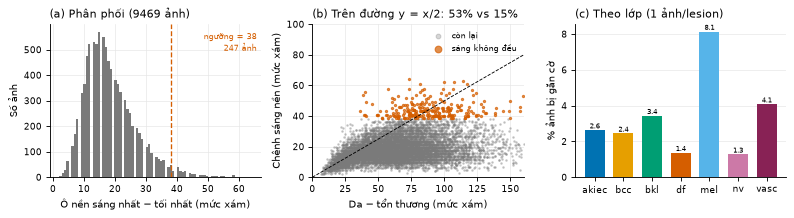

Chênh nền > 1/2 tương phản: 53.0% ảnh bị cờ vs 15.0% phần còn lại
Không đo được (nền quá ít): 204 ảnh
Theo lớp (%): {'akiec': 2.6, 'bcc': 2.4, 'bkl': 3.4, 'df': 1.4, 'mel': 8.1, 'nv': 1.3, 'vasc': 4.1}
[uneven_illum] 247 ảnh (2.5%), 215 lesion → outputs\eda\problem_sets\uneven_illum.csv


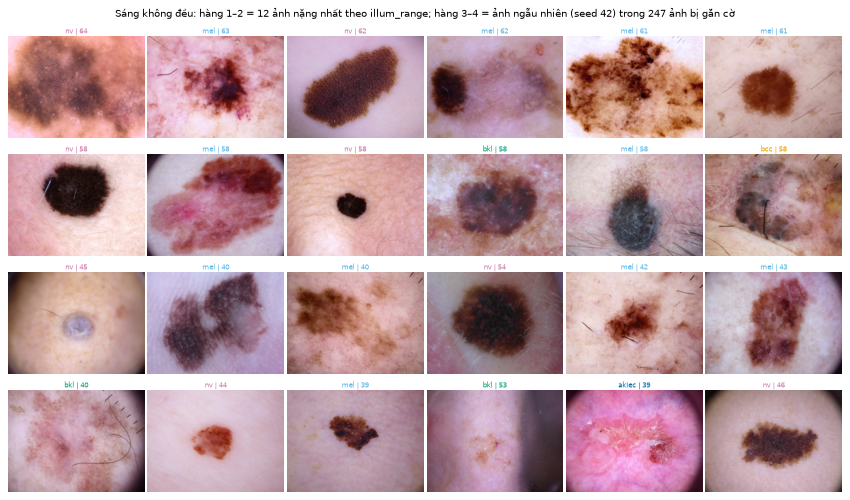

In [7]:
key = "uneven_illum"
nv = df.vignette_frac <= fl.VIG_T
u = df.F_uneven_illum
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
hist_thr(axes[0], df.illum_range[nv], THR[key], "Ô nền sáng nhất − tối nhất (mức xám)")
ax = axes[1]
ax.scatter(df.contrast[nv & ~u], df.illum_range[nv & ~u], s=2, color=pl.OK_COLOR, alpha=0.3, label="còn lại", rasterized=True)
ax.scatter(df.contrast[u], df.illum_range[u], s=4, color=pl.FLAG_COLOR, alpha=0.7, label="sáng không đều", rasterized=True)
ax.plot([0, 160], [0, 80], color="k", lw=0.8, ls="--"); ax.set_xlim(0, 160); ax.set_ylim(0, 100)
frac_above = (df.illum_range[u] > df.contrast[u] / 2).mean()
frac_rest = (df.illum_range[nv & ~u] > df.contrast[nv & ~u] / 2).mean()
ax.set_xlabel("Da − tổn thương (mức xám)"); ax.set_ylabel("Chênh sáng nền (mức xám)")
ax.set_title(f"(b) Trên đường y = x/2: {frac_above:.0%} vs {frac_rest:.0%}", loc="left")
ax.legend(frameon=False, fontsize=7, markerscale=3)
pct = pct_by_class(axes[2], key)
fig.tight_layout(); pl.savefig(fig, "fig05_uneven_illum"); plt.show()
print(f"Chênh nền > 1/2 tương phản: {frac_above:.1%} ảnh bị cờ vs {frac_rest:.1%} phần còn lại")
print(f"Không đo được (nền quá ít): {df.illum_range.isna().sum()} ảnh")
print("Theo lớp (%):", pct.round(1).to_dict())
save_set(key, "illum_range"); grid(key, "illum_range", fmt="{:.0f}", label="Sáng không đều")

### 3.5 Nhiễu Gauss và nhiễu muối–tiêu – mô tả lỗi, kiểm chứng bộ đo

**Mô tả lỗi.** Nhiễu là các biến thiên **ngẫu nhiên** của mức xám không thuộc về nội dung ảnh (mô hình Ch.3: g = f + η).
- **Nhiễu Gauss:** mọi pixel lệch một chút quanh giá trị thật → ảnh "lấm tấm", "hạt" đều khắp ảnh.
- **Nhiễu muối–tiêu (xung):** một số pixel lẻ bị đổi hẳn thành trắng (255) hoặc đen (0).

**Nguyên nhân.** Gauss: nhiễu cảm biến, chụp thiếu sáng phải tăng độ nhạy (ISO). Muối–tiêu: lỗi truyền/ghi dữ liệu, pixel chết của cảm biến.

**Dấu hiệu nhận biết bằng mắt:**
- Gauss: vùng da đáng lẽ phẳng trông **sần, lấm tấm hạt mịn**, rõ nhất ở vùng tối và vùng đồng màu khi phóng to;
- muối–tiêu: **chấm trắng / đen đơn lẻ**, sắc nét, rải rác ngẫu nhiên, không liên quan cấu trúc da.

**Dấu hiệu trên histogram / số liệu:** Gauss làm các đỉnh histogram **bè rộng** ra; ở vùng phẳng, hiệu "ảnh − lọc trung vị 3×3" có độ lệch chuẩn lớn.
Muối–tiêu tạo các **cột nhọn ở đúng mức 0 và 255**; pixel cực trị lệch rất xa trung vị của 8 pixel lân cận.

**Tác hại:** nhiễu tạo cạnh / kết cấu giả, làm sai các bộ lọc phát hiện cạnh (Ch.5); CNN có thể học kết cấu nhiễu đặc trưng của thiết bị.

**Cách đo và bằng chứng trong notebook:**
Trước khi nói "có" hay "không có" nhiễu, phải chứng minh bộ đo **nhìn thấy** được nhiễu.
Lấy 30 ảnh ngẫu nhiên (seed 42), **cộng nhiễu tổng hợp theo mô hình Ch.3** rồi đo lại:
- nhiễu Gauss σ = 2, 5, 10 → σ đo được phải tăng theo;
- nhiễu muối–tiêu p = 0.1%, 1%, 5% → tỉ lệ pixel xung đo được phải ≈ p.

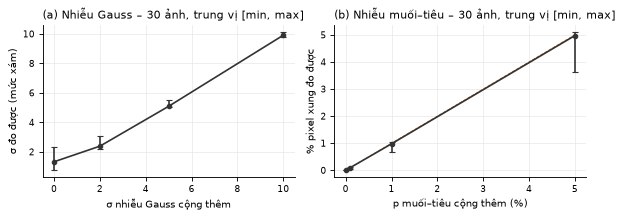

Gauss:
        median   min    max
level                     
0.0      1.33  0.75   2.30
2.0      2.39  2.19   3.06
5.0      5.09  5.02   5.49
10.0     9.91  9.78  10.12
Muối–tiêu (%):
        median    min    max
level                      
0.000   0.000  0.000  0.000
0.001   0.099  0.067  0.110
0.010   0.979  0.694  1.053
0.050   4.971  3.626  5.097


In [8]:
rng = np.random.default_rng(SEED)
sample = df[df.vignette_frac == 0].sample(30, random_state=SEED)
rows = []
for _, r in sample.iterrows():
    g = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    M = qm.masks(g)
    valid = M["inner"] & ~M["hair"]
    for s in [0, 2, 5, 10]:
        gn = np.clip(g + rng.normal(0, s, g.shape), 0, 255).astype(np.uint8) if s else g
        rows.append(dict(kind="gauss", level=s, value=qm.noise_sigma(gn, valid)))
    for p in [0, 0.001, 0.01, 0.05]:
        gn = g.copy(); u_ = rng.random(g.shape)
        gn[u_ < p / 2] = 0; gn[(u_ >= p / 2) & (u_ < p)] = 255
        rows.append(dict(kind="sp", level=p, value=qm.impulse_frac(gn, M["inner"])))
V = pd.DataFrame(rows)
vg = V[V.kind == "gauss"].groupby("level").value.agg(["median", "min", "max"])
vs = V[V.kind == "sp"].groupby("level").value.agg(["median", "min", "max"])
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8))
for ax, v, xl, yl, t in [(axes[0], vg, "σ nhiễu Gauss cộng thêm", "σ đo được (mức xám)", "(a) Nhiễu Gauss"),
                         (axes[1], vs * 100, "p muối–tiêu cộng thêm (%)", "% pixel xung đo được", "(b) Nhiễu muối–tiêu")]:
    x = v.index.values * (100 if "muối" in xl else 1)
    ax.errorbar(x, v["median"], yerr=[v["median"] - v["min"], v["max"] - v["median"]], fmt="o-", color="#333", capsize=3, ms=4)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(f"{t} – 30 ảnh, trung vị [min, max]", loc="left")
axes[1].plot([0, 5], [0, 5], color=pl.FLAG_COLOR, ls="--", lw=0.8)
fig.tight_layout(); pl.savefig(fig, "fig06_noise_validation"); plt.show()
V.to_csv(EDA_DIR / "noise_detector_validation.csv", index=False)
print("Gauss:\n", vg.round(2)); print("Muối–tiêu (%):\n", (vs * 100).round(3))

### 3.6 Nhiễu Gauss và nhiễu muối–tiêu trên dữ liệu thật

**Nhiễu Gauss:** phần dư g − median₃ₓ₃(g) ở vùng phẳng ≈ η. So với σ = 5 tổng hợp ở 3.5 (đã là mức nhìn khó thấy),
σ thật nhỏ hơn hay lớn hơn? Đo thêm ở ảnh 224 (độ phân giải CNN nhìn thấy) – resize có tác dụng như lọc trung bình.

**Muối–tiêu:** nếu bộ đo nhạy (3.5) mà dữ liệu thật ≈ 0 → kết luận **không có**, loại khỏi 2.5.

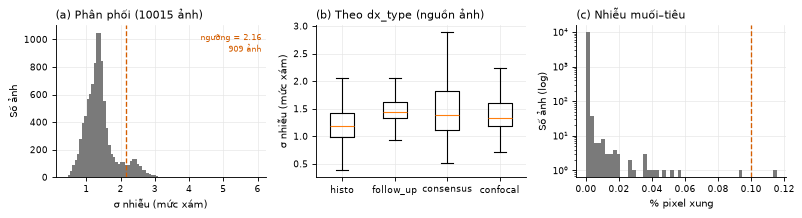

σ trung vị = 1.34, phân vị 99 = 2.76, tối đa = 5.96 mức xám; ảnh 224: trung vị 1.25
Ảnh có σ > 5 (mức tổng hợp ở 3.5): 2
Kruskal–Wallis theo dx_type: ε² = 0.187 (vừa), p = 2.7e-303
Kruskal–Wallis theo dx: ε² = 0.044 (nhỏ), p = 2.0e-68
Muối–tiêu: ảnh có pixel xung: 347; > 0.1%: 1; tối đa 0.1156%
[noise] 734 ảnh (7.3%), 731 lesion → outputs\eda\problem_sets\noise.csv


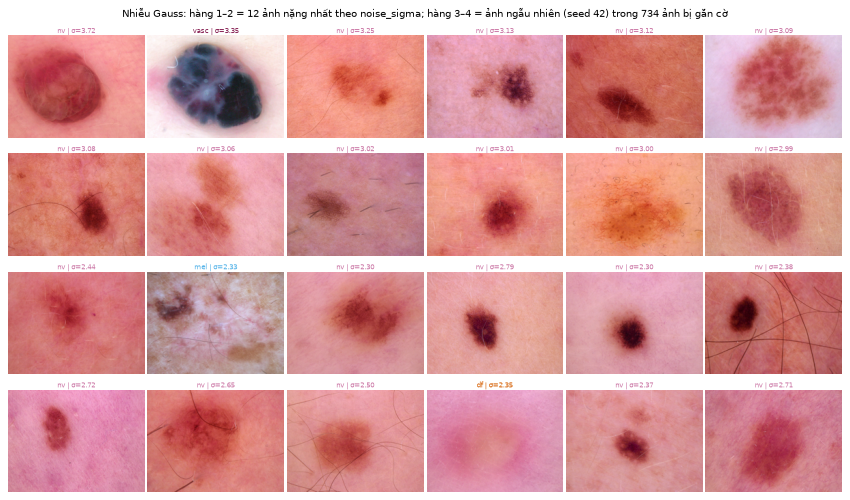

In [9]:
key = "noise"
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
hist_thr(axes[0], df.noise_sigma, THR[key], "σ nhiễu (mức xám)")
ax = axes[1]
order = ["histo", "follow_up", "consensus", "confocal"]
ax.boxplot([df.noise_sigma[df.dx_type == t].dropna() for t in order], tick_labels=order, showfliers=False)
ax.set_ylabel("σ nhiễu (mức xám)"); ax.set_title("(b) Theo dx_type (nguồn ảnh)", loc="left")
ax = axes[2]
ax.hist(df.impulse_frac * 100, bins=50, color=pl.OK_COLOR); ax.set_yscale("log")
ax.axvline(fl.IMPULSE_T * 100, color=pl.FLAG_COLOR, ls="--", lw=1.2)
ax.set_xlabel("% pixel xung"); ax.set_ylabel("Số ảnh (log)"); ax.set_title("(c) Nhiễu muối–tiêu", loc="left")
fig.tight_layout(); pl.savefig(fig, "fig07_noise"); plt.show()
print(f"σ trung vị = {df.noise_sigma.median():.2f}, phân vị 99 = {df.noise_sigma.quantile(.99):.2f}, "
      f"tối đa = {df.noise_sigma.max():.2f} mức xám; ảnh 224: trung vị {df.noise_sigma_224.median():.2f}")
print(f"Ảnh có σ > 5 (mức tổng hợp ở 3.5): {(df.noise_sigma > 5).sum()}")
print(kw("noise_sigma", "dx_type")); print(kw("noise_sigma", "dx"))
print(f"Muối–tiêu: ảnh có pixel xung: {(df.impulse_frac > 0).sum()}; > 0.1%: {df.F_impulse.sum()}; "
      f"tối đa {df.impulse_frac.max():.4%}")
save_set(key, "noise_sigma"); grid(key, "noise_sigma", fmt="σ={:.2f}", label="Nhiễu Gauss")

### 3.7 Lông – nhiễu dạng nét tối mảnh

**Mô tả lỗi.** Sợi lông (tóc) nằm **đè lên da và tổn thương** – có thể coi là một loại nhiễu dạng nét: không thuộc về đối tượng cần nhận dạng.

**Nguyên nhân.** Tổn thương ở vùng nhiều lông (da đầu, mặt, ngực, chân) và không cạo lông trước khi chụp.

**Dấu hiệu nhận biết bằng mắt:**
- các **nét tối, mảnh (2–10 px), dài, cong**, cắt ngang ảnh, thường nhiều sợi song song hoặc đan chéo;
- lông đè lên tổn thương, che mất một phần mạng sắc tố và bờ tổn thương;
- có cả lông bạc/trắng (sáng hơn da) ở người lớn tuổi.

**Dấu hiệu trên histogram / số liệu:** lông ít ảnh hưởng tới histogram (diện tích nhỏ) nên **không** nhìn thấy qua histogram;
nhận biết bằng phép **black-hat** (đóng − ảnh): nét tối hẹp hơn phần tử cấu trúc cho phản hồi cao; tỉ lệ pixel lông lớn.

**Tác hại:** lọc trung vị 3×3 không xóa được (sợi lông rộng hơn cửa sổ lọc); lông tạo cạnh mạnh giả, che chi tiết chẩn đoán,
và CNN có thể học "nhiều lông ↔ vùng cơ thể ↔ lớp bệnh".

**Cách đo và bằng chứng trong notebook:**

**Đo:** black-hat = phép đóng(ảnh) − ảnh (phần tử cấu trúc 17×17 lớn hơn bề rộng sợi lông) → ngưỡng ≥ 20, bỏ đốm < 60 px.

**Vì sao là vấn đề:** sợi lông dày 2–10 px, dài hàng trăm px – lọc trung vị 3×3 (Ch.3) không xóa được,
nhưng lại che tổn thương và tạo cạnh giả.

**Kiểm chứng chỉ số đo đúng:** da đầu (scalp) phải nhiều lông hơn lòng bàn tay/chân (acral).

**Còn sau resize 224?** So tỉ lệ lông ở ảnh gốc và ảnh 224.

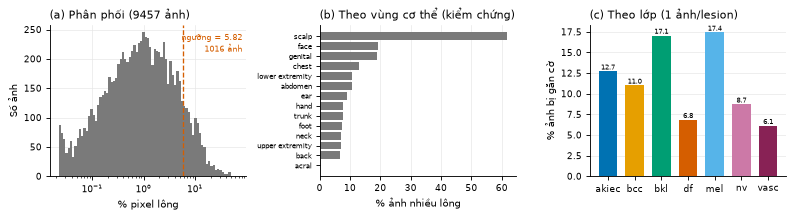

Spearman ρ (lông ảnh gốc vs ảnh 224) = 0.86
Theo vùng cơ thể (%): {'acral': 0.0, 'back': 6.7, 'upper extremity': 7.0, 'neck': 7.1, 'foot': 7.2, 'trunk': 7.5, 'hand': 7.8, 'ear': 8.9, 'abdomen': 10.7, 'lower extremity': 10.7, 'chest': 13.0, 'genital': 18.8, 'face': 19.2, 'scalp': 61.7}
Theo lớp (%): {'akiec': 12.7, 'bcc': 11.0, 'bkl': 17.1, 'df': 6.8, 'mel': 17.4, 'nv': 8.7, 'vasc': 6.1}
[hair] 1016 ảnh (10.1%), 852 lesion → outputs\eda\problem_sets\hair.csv


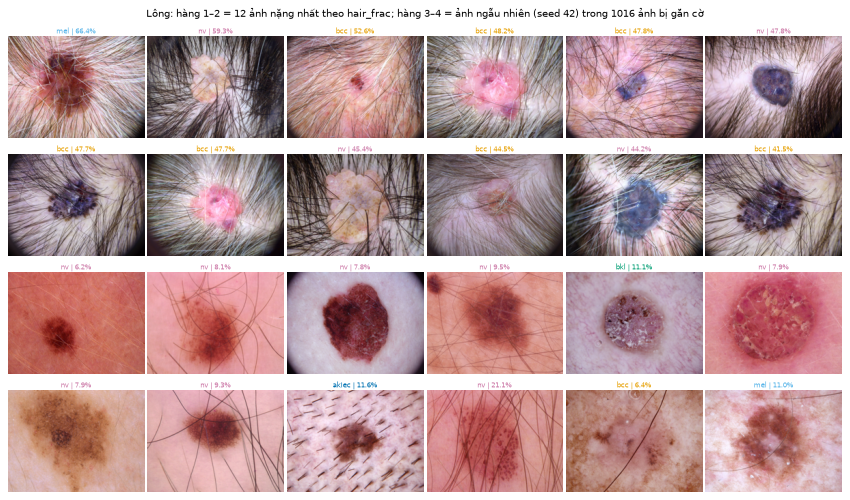

In [10]:
key = "hair"
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
hist_thr(axes[0], df.hair_frac * 100, THR[key] * 100, "% pixel lông", log=True)
ax = axes[1]
loc = df[df.localization != "unknown"].groupby("localization").F_hair.mean().sort_values() * 100
ax.barh(loc.index, loc.values, color=pl.OK_COLOR)
ax.set_xlabel("% ảnh nhiều lông"); ax.set_title("(b) Theo vùng cơ thể (kiểm chứng)", loc="left")
ax.tick_params(axis="y", labelsize=6.5); ax.grid(axis="y", visible=False)
pct = pct_by_class(axes[2], key)
fig.tight_layout(); pl.savefig(fig, "fig08_hair"); plt.show()
rho = sps.spearmanr(df.hair_frac, df.hair_frac_224, nan_policy="omit")[0]
print(f"Spearman ρ (lông ảnh gốc vs ảnh 224) = {rho:.2f}")
print("Theo vùng cơ thể (%):", loc.round(1).to_dict()); print("Theo lớp (%):", pct.round(1).to_dict())
save_set(key, "hair_frac"); grid(key, "hair_frac", fmt="{:.1%}", label="Lông")

## 4. Tổng hợp
(a) Số ảnh mỗi vấn đề. (b) Effect size ε² của chỉ số theo lớp bệnh (`dx`) và nguồn ảnh (`dx_type`):
nếu ε² theo `dx_type` > theo `dx`, chỉ số phản ánh **cách chụp** nhiều hơn bệnh → cảnh báo CNN có thể học "đường tắt".
(c) Tương quan Spearman giữa các chỉ số: |ρ| ≥ 0.7 nghĩa là hai chỉ số đo cùng một hiện tượng.

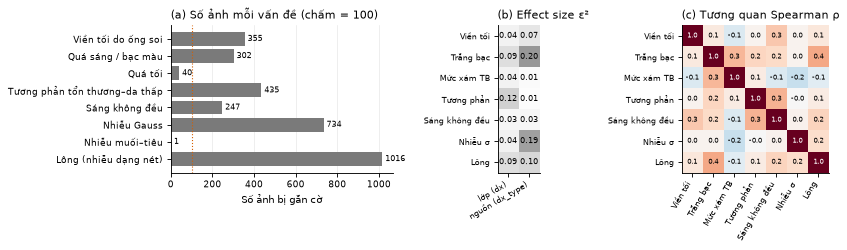

{'Viền tối do ống soi': 355, 'Quá sáng / bạc màu': 302, 'Quá tối': 40, 'Tương phản tổn thương–da thấp': 435, 'Sáng không đều': 247, 'Nhiễu Gauss': 734, 'Nhiễu muối–tiêu': 1, 'Lông (nhiễu dạng nét)': 1016}


group,dx,dx_type
metric,,
Viền tối,0.042,0.071
Trắng bạc,0.088,0.197
Mức xám TB,0.043,0.015
Tương phản,0.115,0.008
Sáng không đều,0.030,0.028
Nhiễu σ,0.044,0.187
Lông,0.089,0.104


In [11]:
KEYS = ["vignette", "overexposed", "underexposed", "low_contrast", "uneven_illum", "noise", "impulse", "hair"]
NAMES = dict(zip(RULES.key, RULES.problem))
MAIN = {"vignette_frac": "Viền tối", "bright_frac": "Trắng bạc", "gray_mean": "Mức xám TB", "contrast": "Tương phản",
        "illum_range": "Sáng không đều", "noise_sigma": "Nhiễu σ", "hair_frac": "Lông"}
counts = pd.Series({NAMES[k]: int(df["F_" + k].sum()) for k in KEYS})
rows = []
for m in MAIN:
    for g in ["dx", "dx_type"]:
        rows.append(dict(metric=MAIN[m], group=g, **st.kruskal_eps2(les, m, g)))
E = pd.DataFrame(rows); E["p_holm"] = st.holm(E.p)
E.to_csv(EDA_DIR / "table_kruskal_eps2.csv", index=False)
Ep = E.pivot(index="metric", columns="group", values="eps2").reindex(list(MAIN.values()))
corr = df[list(MAIN)].corr("spearman").rename(index=MAIN, columns=MAIN)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1.1, 0.8, 1.1]))
ax = axes[0]
ax.barh(counts.index, counts.values, color=pl.OK_COLOR); ax.invert_yaxis()
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v}", va="center", fontsize=7)
ax.axvline(100, color=pl.FLAG_COLOR, ls=":", lw=1); ax.set_xlabel("Số ảnh bị gắn cờ")
ax.set_title("(a) Số ảnh mỗi vấn đề (chấm = 100)", loc="left"); ax.grid(axis="y", visible=False)
ax = axes[1]
im = ax.imshow(Ep, cmap="Greys", vmin=0, vmax=0.4)
ax.set_xticks(range(2), ["lớp (dx)", "nguồn (dx_type)"], rotation=30, ha="right", fontsize=7); ax.set_yticks(range(len(Ep)), Ep.index, fontsize=7)
for i in range(len(Ep)):
    for j in range(2):
        ax.text(j, i, f"{Ep.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if Ep.iloc[i, j] > .2 else "k")
ax.set_title("(b) Effect size ε²", loc="left"); ax.grid(False)
ax = axes[2]
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(MAIN)), corr.columns, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(len(MAIN)), corr.index, fontsize=7)
for i in range(len(MAIN)):
    for j in range(len(MAIN)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6, color="w" if abs(corr.iloc[i, j]) > .6 else "k")
ax.set_title("(c) Tương quan Spearman ρ", loc="left"); ax.grid(False)
fig.tight_layout(); pl.savefig(fig, "fig09_summary"); plt.show()
print(counts.to_dict()); Ep.round(3)

In [12]:
# Lưu cờ của từng ảnh (True/False cho mỗi vấn đề) để mục 2.5 chọn tập ảnh thử nghiệm
CONFIRMED = ["vignette", "overexposed", "low_contrast", "uneven_illum", "noise", "hair"]
df[["image_id", "lesion_id", "dx", "split"] + [c for c in df.columns if c.startswith("F_")]].to_csv(EDA_DIR / "image_flags.csv", index=False)
print("Đã lưu", EDA_DIR / "image_flags.csv")

Đã lưu outputs\eda\image_flags.csv


## 5. Liên hệ với lỗi CNN – **TODO: chờ dự đoán baseline ngoài mẫu**
Khi có `outputs/baseline/predictions*.csv` (cột `image_id`, `pred`; dự đoán trên ảnh không dùng để train),
ô dưới tự tính tỉ lệ lỗi ở ảnh bị gắn cờ so với không bị gắn cờ, cho từng vấn đề.

In [13]:
pred_files = sorted(Path("outputs/baseline").glob("predictions*.csv")) if Path("outputs/baseline").exists() else []
if not pred_files:
    print("TODO: chưa có dự đoán baseline ngoài mẫu → chưa kết luận về liên hệ với lỗi CNN.")
else:
    P = pd.concat([pd.read_csv(f) for f in pred_files]).merge(df, on="image_id")
    P["err"] = P["pred"] != P["label"]
    print(pd.DataFrame({k: dict(n=P["F_" + k].sum(), err_flag=P.err[P["F_" + k]].mean(), err_rest=P.err[~P["F_" + k]].mean())
                        for k in CONFIRMED}).T)

TODO: chưa có dự đoán baseline ngoài mẫu → chưa kết luận về liên hệ với lỗi CNN.


## 6. Bảng kết luận EDA
Cột cuối là **dự kiến** cho 2.5, không phải kết luận. "Liên quan lỗi CNN" để TODO đến khi có baseline.

In [14]:
def n(k): return int(df["F_" + k].sum())
concl = pd.DataFrame([
    ("Viền tối ống soi", "Có", f"{n('vignette')} ảnh; đỉnh mức xám 0–20 trong histogram (Hình 2)", "Bỏ viền khỏi ảnh / khỏi thống kê histogram"),
    ("Quá sáng / bạc màu", "Có", f"{n('overexposed')} ảnh; histogram lệch phải (Hình 3)", "Gamma γ > 1, cân bằng histogram"),
    ("Quá tối", "Không (quá ít)", f"{n('underexposed')} ảnh dưới ngưỡng box plot (Hình 3)", "Không xử lý riêng"),
    ("Tương phản thấp", "Có", f"{n('low_contrast')} ảnh; histogram hẹp 1 đỉnh (Hình 4)", "Giãn histogram, cân bằng histogram"),
    ("Sáng không đều", "Có", f"{n('uneven_illum')} ảnh; {frac_above:.0%} có chênh nền > 1/2 tương phản (Hình 5)", "CLAHE (cân bằng cục bộ)"),
    ("Nhiễu Gauss", "Có nhưng nhỏ", f"σ trung vị {df.noise_sigma.median():.2f} mức xám; {n('noise')} ảnh trên ngưỡng (Hình 6–7)", "Lọc trung vị / Gauss: thử, kỳ vọng tác động nhỏ"),
    ("Nhiễu muối–tiêu", "Không", f"{n('impulse')} ảnh > 0.1% pixel xung; bộ đo nhạy với p = 0.1% (Hình 6)", "Loại khỏi 2.5"),
    ("Lông", "Có", f"{n('hair')} ảnh; da đầu {loc.get('scalp', np.nan):.0f}% vs acral {loc.get('acral', np.nan):.0f}% (Hình 8)", "Black-hat + inpainting"),
], columns=["Vấn đề", "Tồn tại?", "Bằng chứng", "Dự kiến cho 2.5"])
concl.insert(3, "Liên quan lỗi CNN?", "TODO: chờ baseline")
concl.to_csv(EDA_DIR / "eda_conclusion.csv", index=False)
RULES.to_csv(EDA_DIR / "table_flag_rules.csv", index=False)
concl

,Vấn đề,Tồn tại?,Bằng chứng,Liên quan lỗi CNN?,Dự kiến cho 2.5
0,Viền tối ống soi,Có,355 ảnh; đỉnh mức xám 0–20 trong histogram (Hì...,TODO: chờ baseline,Bỏ viền khỏi ảnh / khỏi thống kê histogram
1,Quá sáng / bạc màu,Có,302 ảnh; histogram lệch phải (Hình 3),TODO: chờ baseline,"Gamma γ > 1, cân bằng histogram"
2,Quá tối,Không (quá ít),40 ảnh dưới ngưỡng box plot (Hình 3),TODO: chờ baseline,Không xử lý riêng
3,Tương phản thấp,Có,435 ảnh; histogram hẹp 1 đỉnh (Hình 4),TODO: chờ baseline,"Giãn histogram, cân bằng histogram"
4,Sáng không đều,Có,247 ảnh; 53% có chênh nền > 1/2 tương phản (Hì...,TODO: chờ baseline,CLAHE (cân bằng cục bộ)
5,Nhiễu Gauss,Có nhưng nhỏ,σ trung vị 1.34 mức xám; 734 ảnh trên ngưỡng (...,TODO: chờ baseline,"Lọc trung vị / Gauss: thử, kỳ vọng tác động nhỏ"
6,Nhiễu muối–tiêu,Không,1 ảnh > 0.1% pixel xung; bộ đo nhạy với p = 0....,TODO: chờ baseline,Loại khỏi 2.5
7,Lông,Có,1016 ảnh; da đầu 62% vs acral 0% (Hình 8),TODO: chờ baseline,Black-hat + inpainting


## 7. Kết luận: các vấn đề chất lượng ảnh trong HAM10000

Trên toàn bộ **10 015 ảnh** (7 470 lesion, cùng kích thước 600×450, RGB), xét 8 loại lỗi chất lượng ảnh thuộc phạm vi Chương 3.
Số liệu dưới đây lấy từ đầu ra của các ô phía trên.

**Các vấn đề CÓ tồn tại (đủ ảnh để đưa vào thí nghiệm ở 2.5):**

- **Lông che phủ – 1 016 ảnh (10,1%).** Nét tối mảnh đè lên tổn thương. Chỉ số đo đúng: da đầu 61,7% ảnh nhiều lông, lòng bàn tay/chân 0%.
  Lông vẫn còn sau resize 224 (ρ = 0,86) nên CNN thực sự nhìn thấy. Nhiều nhất ở mel (17,4%) và bkl (17,1%).
  → Xử lý: black-hat + inpainting.
- **Nhiễu Gauss – 734 ảnh (7,3%) trên ngưỡng, nhưng mức nhiễu nhỏ.** σ trung vị chỉ 1,34 mức xám (phân vị 99 = 2,76; chỉ 2 ảnh có σ > 5).
  Bộ đo đã được kiểm chứng (cộng σ = 5 đo được 5,09). Mức nhiễu phụ thuộc nguồn ảnh (ε² = 0,187) hơn là lớp bệnh (ε² = 0,044).
  → Xử lý: lọc trung vị / Gauss, kỳ vọng tác động nhỏ.
- **Tương phản tổn thương–da thấp – 435 ảnh (4,3%).** Histogram hẹp, 1 đỉnh: khoảng phân vị 5–95 là 38 mức xám (so với 84).
  Tập trung ở bcc (14,1%), akiec (12,7%), df (9,6%); gắn với loại tổn thương (ε² theo lớp = 0,115), không gắn với nguồn ảnh.
  → Xử lý: giãn / cân bằng histogram.
- **Viền tối do ống soi – 355 ảnh (3,5%).** Đỉnh giả ở mức xám 0–20: 5,56% pixel so với 0,018% ở ảnh không viền.
  Nhiều ở mel (8,6%) và bkl (6,7%), ít ở nv (1,4%).
  → Xử lý: bỏ viền khỏi ảnh / khỏi thống kê histogram.
- **Quá sáng (bạc màu) – 302 ảnh (3,0%).** Histogram lệch phải: 62,2% pixel có mức xám ≥ 200 (so với 5,1%); độ bão hòa da 32,1 so với 63,1.
  Phân bố đều giữa các lớp (2,1–4,6%).
  → Xử lý: biến đổi gamma (γ > 1), cân bằng histogram.
- **Sáng không đều – 247 ảnh (2,5%).** Nền da chênh > 38 mức xám giữa các vùng; 53% số ảnh này có nền tối đi hơn nửa độ tương phản
  (so với 15% ở phần còn lại) → phân ngưỡng / cân bằng histogram toàn cục sẽ sai. Nhiều ở mel (8,1%).
  → Xử lý: CLAHE (cân bằng histogram cục bộ).


**Lưu ý chung:**

- Các vấn đề gần như **độc lập** với nhau (mọi cặp chỉ số có |ρ| ≤ 0,4), nên mỗi phương pháp ở 2.5 nhắm vào một vấn đề riêng.
- Quá sáng, nhiễu và viền tối khác nhau theo **nguồn ảnh** (`dx_type`) nhiều hơn theo lớp bệnh → CNN có thể học dấu vết thiết bị chụp;
  đây là giả thuyết, cần kiểm chứng.
- Liên hệ giữa các vấn đề này và lỗi của CNN: **TODO** – chờ dự đoán baseline ngoài mẫu.